# JS10 - Lab 2
## XOR Logic Values with MLP

XOR (*exclusive OR*) bernilai benar hanya jika **salah satu** input benar, bukan keduanya dan
bukan tidak ada. Masalah ini **tidak linearly separable**, sehingga Perceptron satu lapis tidak
dapat menyelesaikannya - dibutuhkan *hidden layer* (MLP).

### Step 1 - Import Libraries

In [1]:
from sklearn.neural_network import MLPClassifier
import numpy as np

### Step 2 - Create Data

In [2]:
y = [0, 1, 1, 0]                      # labels
X = [[0, 0], [0, 1], [1, 0], [1, 1]]  # data

print("X:", X)
print("y:", y)

X: [[0, 0], [0, 1], [1, 0], [1, 1]]
y: [0, 1, 1, 0]


### Step 3 - Fit the Model

`hidden_layer_sizes=(2,)` berarti satu hidden layer dengan 2 neuron - jumlah minimum yang
secara teori cukup untuk merepresentasikan XOR. `activation='logistic'` (sigmoid) dan
`solver='lbfgs'` dipakai sesuai modul.

In [3]:
# Fit model
clf = MLPClassifier(solver='lbfgs', activation='logistic', hidden_layer_sizes=(2,), max_iter=100, random_state=20)
clf.fit(X, y)

print("Jumlah iterasi yang dijalankan:", clf.n_iter_)
print("Bobot input->hidden:", np.round(clf.coefs_[0], 3))
print("Bobot hidden->output:", np.round(clf.coefs_[1], 3))

Jumlah iterasi yang dijalankan: 36
Bobot input->hidden: [[6.118 6.357]
 [5.791 6.146]]
Bobot hidden->output: [[-14.955]
 [ 14.531]]


### Step 4 - Prediction

In [4]:
pred = clf.predict(X)
print('Accuracy: %s' % clf.score(X, y))
for i,p in enumerate(pred[:10]):
    print('True: %s, Predicted: %s' % (y[i], p))

Accuracy: 1.0
True: 0, Predicted: 0
True: 1, Predicted: 1
True: 1, Predicted: 1
True: 0, Predicted: 0


### Step 5 - Inspect the Probability per Class

Nilai `predict_proba` memperlihatkan seberapa yakin model pada setiap kelas. Untuk XOR,
prediksi yang benar akan memberi probabilitas mendekati 0 atau 1.

In [5]:
proba = clf.predict_proba(X)
for xi, yi, p in zip(X, y, proba):
    print(f"X={xi}  true={yi}  P(class0)={p[0]:.4f}  P(class1)={p[1]:.4f}")

X=[0, 0]  true=0  P(class0)=0.9983  P(class1)=0.0017
X=[0, 1]  true=1  P(class0)=0.0016  P(class1)=0.9984
X=[1, 0]  true=1  P(class0)=0.0017  P(class1)=0.9983
X=[1, 1]  true=0  P(class0)=0.9986  P(class1)=0.0014


### Step 6 - Comparison with a Single-Layer Perceptron

Sebagai pembanding, `MLPClassifier` tanpa hidden layer (`hidden_layer_sizes=()`) adalah model
linear - setara Perceptron. Model ini tidak akan mampu menyelesaikan XOR.

In [6]:
linear = MLPClassifier(solver='lbfgs', activation='logistic', hidden_layer_sizes=(),
                       max_iter=1000, random_state=20)
linear.fit(X, y)

print("Linear model accuracy:", linear.score(X, y))
print("Prediksi linear       :", linear.predict(X))
print("Target                :", y)

Linear model accuracy: 0.25
Prediksi linear       : [0 0 0 1]
Target                : [0, 1, 1, 0]


### Step 7 - Experiment: Number of Hidden Neurons

Jumlah neuron pada hidden layer menentukan kapasitas model. Berikut hasil untuk beberapa
konfigurasi (`random_state` tetap, sehingga hasilnya deterministik).

In [7]:
rows = []
for sizes in [(1,), (2,), (3,), (2, 2), (4,)]:
    model = MLPClassifier(solver='lbfgs', activation='logistic',
                          hidden_layer_sizes=sizes, max_iter=1000, random_state=20)
    model.fit(X, y)
    rows.append((sizes, model.score(X, y), model.n_iter_))

print(f"{'hidden_layer_sizes':>20} | {'accuracy':>8} | {'iterasi':>7}")
print("-" * 42)
for sizes, acc, it in rows:
    print(f"{str(sizes):>20} | {acc:>8.2f} | {it:>7}")

  hidden_layer_sizes | accuracy | iterasi
------------------------------------------
                (1,) |     0.75 |      34
                (2,) |     1.00 |      36
                (3,) |     1.00 |      74
              (2, 2) |     1.00 |      62
                (4,) |     0.50 |      58


### Step 8 - Visualization of the Decision Boundary

XOR tidak dapat dipisahkan oleh satu garis, sehingga batas keputusannya berbentuk dua region
yang saling bersilangan.

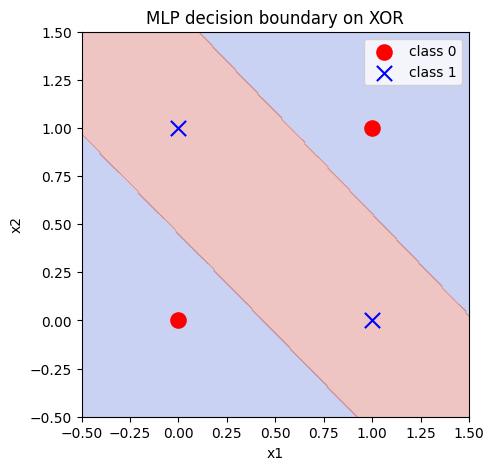

In [8]:
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
Z = clf.predict(grid).reshape(xx.shape)

plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
for label, marker, color in [(0, 'o', 'red'), (1, 'x', 'blue')]:
    pts = np.array([x for x, t in zip(X, y) if t == label])
    plt.scatter(pts[:, 0], pts[:, 1], marker=marker, color=color, s=120,
                label=f'class {label}')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('MLP decision boundary on XOR')
plt.legend()
plt.show()

### Step 9 - Conclusion

* Satu lapis neuron tanpa hidden layer hanya dapat membentuk batas keputusan linear, sehingga
  **gagal pada XOR** (akurasi 0.25 - lebih buruk daripada menebak).
* Dengan satu hidden layer berisi 2 neuron dan aktivasi non-linear (sigmoid), MLP dapat
  merepresentasikan XOR dengan akurasi 1.0.
* Jumlah neuron bukan satu-satunya penentu: konfigurasi `(1,)` hanya mencapai 0.75 dan `(4,)`
  bahkan 0.50. Penyebabnya adalah **local minimum** - dengan `solver='lbfgs'` dan inisialisasi
  acak, sebagian konfigurasi terjebak pada solusi yang bukan pemisah XOR yang benar.
  `(2,)` berhasil karena dua neuron cukup untuk membentuk dua region yang bersilangan.
* Ini menunjukkan peran *hidden layer* dan *activation function*: keduanya yang membuat jaringan
  mampu memodelkan hubungan non-linear.